# NadiKampus — Model Sentimen: Bandingkan Metode & Terapkan ke Seluruh Korpus

Lanjutan dari dua notebook pelabelan (GForm dan Telegram). Notebook ini:

1. memuat gold set `nadikampus_sentiment_labeled.parquet` (sudah punya kolom `split`),
2. membandingkan metode: **baseline mayoritas, lexicon InSet, model Indonesia siap pakai, TF-IDF + LogReg, fine-tuning IndoBERTweet**,
3. memilih metode terbaik **berdasarkan val** (bukan test), lalu melaporkan test **per sumber**,
4. menerapkan metode terpilih ke seluruh korpus dan menyimpan `sentiment`, `sentiment_prob`, `sentiment_low_conf`.

**Aturan evaluasi (sesuai Pedoman):** ukuran utama **Macro F1**, plus F1 per kelas dan confusion matrix; **Telegram dan GForm dilaporkan terpisah**. Test set hanya dilihat sekali, setelah metode dipilih.

> Catatan jujur soal ukuran data: dengan 300 post Telegram, test Telegram hanya ±45 post. Macro F1 di sini **sangat bergejolak**, jadi notebook ini juga menghitung selang kepercayaan bootstrap. Selisih kecil antar-metode jangan diartikan sebagai "yang satu lebih baik".

## 1. Setup & konfigurasi

In [1]:
# Jalankan sekali kalau belum terpasang, lalu restart kernel:
# %pip install pandas pyarrow scikit-learn matplotlib
# Untuk model Hugging Face / fine-tuning (GPU NVIDIA: pasang torch build CUDA dari pytorch.org lebih dulu):
# %pip install transformers accelerate sentencepiece

In [2]:
import os, re, copy, json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

pd.set_option("display.width", 200)

In [3]:
# ====================== KONFIGURASI ======================
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir()), Path.cwd())
LABELED_PATH = ROOT / "data" / "processed" / "nadikampus_sentiment_labeled.parquet"
CORPUS_PATH = next((p for p in [ROOT / "data" / "processed" / "nadikampus_corpus_all.parquet",
                                ROOT / "data" / "nadikampus_corpus_all.parquet",
                                ROOT / "nadikampus_corpus_all.parquet"] if p.exists()),
                   ROOT / "data" / "processed" / "nadikampus_corpus_all.parquet")
OUT_DIR = ROOT / "data" / "outputs_teks"          # sama dengan notebook topic detection
LEX_DIR = ROOT / "data" / "lexicon"

SEED = 42
SENT_LABELS = ["negative", "neutral", "positive"]
LOW_CONF = 0.60            # prediksi dengan prob < ini ditandai low_conf (jangan dihitung di donut dashboard)

# --- metode opsional (yang mahal bisa dimatikan)
RUN_INSET = True           # butuh unduh lexicon sekali (atau taruh positive.tsv / negative.tsv di data/lexicon/)
RUN_HF_PRETRAINED = True   # model sentimen Indonesia siap pakai, tanpa pelatihan
RUN_FINETUNE = True        # fine-tuning IndoBERTweet; ~menit di GPU 8 GB, sangat lambat di CPU

HF_PRETRAINED = "w11wo/indonesian-roberta-base-sentiment-classifier"   # VERIFIKASI nama & label di Hugging Face
HF_LABEL_MAP = {}          # kalau labelnya LABEL_0/1/2, isi mis. {"LABEL_0": "positive", "LABEL_1": "neutral", "LABEL_2": "negative"}
FT_BASE = "indolem/indobertweet-base-uncased"                          # VERIFIKASI nama di Hugging Face
FT_EPOCHS, FT_LR, FT_BS, FT_MAXLEN = 5, 3e-5, 16, 128

OUT_DIR.mkdir(parents=True, exist_ok=True); LEX_DIR.mkdir(parents=True, exist_ok=True)

## 2. Muat gold set

Kolom penting: `model_input` (Telegram = `text_clean`; GForm = pertanyaan + jawaban), `label_sentiment`, `split`, `source`.

In [4]:
d = pd.read_parquet(LABELED_PATH)
d["source"] = d["source"].astype(str)
tr, va, te = (d[d["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
display(pd.crosstab([d["source"], d["split"]], d["label_sentiment"]).reindex(columns=SENT_LABELS, fill_value=0))

if (d["source"] == "telegram").sum() == 0:
    print("[!] Belum ada label Telegram di dataset -> jalankan notebook Telegram, lalu bagian 8 notebook GForm.")

label_sentiment  negative  neutral  positive
source   split                              
gform    test          21       14        48
         train         97       66       224
         val           21       14        48
telegram test         102      132        12
         train        474      616        53
         val          102      132        11

## 3. Fungsi evaluasi (Macro F1 + bootstrap)

`evaluate()` menampilkan Macro F1 per sumber dengan selang kepercayaan 95% (bootstrap atas dokumen).

In [5]:
rng = np.random.default_rng(SEED)

def macro_f1(y, p):
    return f1_score(y, p, labels=SENT_LABELS, average="macro", zero_division=0)

def boot_ci(y, p, n=1000):
    y, p = np.asarray(y), np.asarray(p)
    if len(y) < 10:
        return (np.nan, np.nan)
    s = [macro_f1(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return tuple(np.percentile(s, [2.5, 97.5]))

def score_table(df, pred, with_ci=False):
    rows = []
    for src, g in df.assign(pred=pred).groupby("source"):
        r = {"source": src, "n": len(g), "macro_f1": macro_f1(g["label_sentiment"], g["pred"]),
             "accuracy": float((g["label_sentiment"] == g["pred"]).mean())}
        f = f1_score(g["label_sentiment"], g["pred"], labels=SENT_LABELS, average=None, zero_division=0)
        r.update({f"f1_{k}": v for k, v in zip(SENT_LABELS, f)})
        if with_ci:
            r["ci95"] = tuple(round(x, 2) for x in boot_ci(g["label_sentiment"], g["pred"]))
        rows.append(r)
    return pd.DataFrame(rows).set_index("source").round(3)

def to_labels(proba):
    return np.array(SENT_LABELS)[np.asarray(proba).argmax(1)]

# register: nama -> {"val": label_array, "test": label_array, "proba_fn": callable(list[str]) -> proba | None}
REG = {}

## 4. Metode A: baseline mayoritas

Batas bawah. Kalau metode lain tidak jauh di atas ini (khususnya Macro F1), metode itu belum belajar apa-apa. Mayoritas dihitung **per sumber** dari train.

In [6]:
maj = tr.groupby("source")["label_sentiment"].agg(lambda s: s.value_counts().idxmax()).to_dict()
REG["mayoritas"] = {"val": va["source"].map(maj).values, "test": te["source"].map(maj).values, "proba_fn": None}
print("Kelas mayoritas per sumber:", maj)
score_table(va, REG["mayoritas"]["val"])

Kelas mayoritas per sumber: {'gform': 'positive', 'telegram': 'neutral'}


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive
source,,,,,,
gform,83,0.244,0.578,0.0,0.0,0.733
telegram,245,0.233,0.539,0.0,0.7,0.000


## 5. Metode B: lexicon InSet

Baseline berbasis kamus: skor = (jumlah kata positif - jumlah kata negatif). Skor > 0 positif, < 0 negatif, 0 netral. Dipakai pada `text_norm` (hanya jawaban/post, **tanpa** teks pertanyaan, supaya kata seperti "kendala" di pertanyaan tidak ikut dihitung).

Catatan dari percobaan sebelumnya: InSet pada data menfess sangat condong negatif (≈81%). Anggap ini pembanding kasar, bukan kandidat utama.

Lexicon diunduh dari repo InSet (fajri91/InSet). Kalau unduhan gagal (jaringan kampus/proxy), unduh manual `positive.tsv` dan `negative.tsv` lalu taruh di `data/lexicon/`.

In [7]:
LEX = None
if RUN_INSET:
    base = "https://raw.githubusercontent.com/fajri91/InSet/master/"
    try:
        for fn in ("positive.tsv", "negative.tsv"):
            if not (LEX_DIR / fn).exists():
                urllib.request.urlretrieve(base + fn, LEX_DIR / fn)
        def load_lex(fn):
            x = pd.read_csv(LEX_DIR / fn, sep="\t")
            return dict(zip(x.iloc[:, 0].astype(str).str.lower(), x.iloc[:, 1].astype(float)))
        LEX = {**load_lex("negative.tsv"), **load_lex("positive.tsv")}
        print(f"Lexicon dimuat: {len(LEX)} kata")
    except Exception as e:
        print(f"[!] InSet dilewati: {e}")

if LEX:
    def inset_predict(df):
        out = []
        for t in df["text_norm"].fillna("").astype(str):
            s = sum(LEX.get(w, 0.0) for w in re.findall(r"\w+", t.lower()))
            out.append("positive" if s > 0 else "negative" if s < 0 else "neutral")
        return np.array(out)
    REG["inset"] = {"val": inset_predict(va), "test": inset_predict(te), "proba_fn": None}
    print(pd.Series(REG["inset"]["val"]).value_counts(normalize=True).round(2).to_dict())
    display(score_table(va, REG["inset"]["val"]))

Lexicon dimuat: 9071 kata
{'negative': 0.52, 'positive': 0.4, 'neutral': 0.08}


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive
source,,,,,,
gform,83,0.362,0.434,0.508,0.071,0.506
telegram,245,0.281,0.339,0.551,0.111,0.182


## 6. Metode C: TF-IDF + Logistic Regression

Fitur: n-gram **kata** (1-2) dan n-gram **karakter** (2-5, `char_wb`). Karakter penting untuk menfess: menangkap slang, salah ketik, dan emoji yang tidak tertangkap tokenizer kata. `class_weight="balanced"` karena Telegram timpang ke Netral. Nilai `C` dipilih dari val.

In [8]:
def make_vec():
    return make_union(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True))

best = None
for C in (0.3, 1, 3, 10):
    vec = make_vec()
    Xtr = vec.fit_transform(tr["model_input"])
    clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced").fit(Xtr, tr["label_sentiment"])
    pv = clf.predict(vec.transform(va["model_input"]))
    s = np.mean([macro_f1(g["label_sentiment"], g["p"]) for _, g in va.assign(p=pv).groupby("source")])
    print(f"C={C:<4} rata-rata Macro F1 val per sumber = {s:.3f}")
    if best is None or s > best[0]:
        best = (s, C, vec, clf)

_, C_BEST, vec_tf, clf_tf = best
print("C terpilih:", C_BEST)
tfidf_proba = lambda texts: clf_tf.predict_proba(vec_tf.transform(texts))[:, [list(clf_tf.classes_).index(k) for k in SENT_LABELS]]
REG["tfidf_logreg"] = {"val": to_labels(tfidf_proba(va["model_input"])), "test": to_labels(tfidf_proba(te["model_input"])),
                       "proba_fn": tfidf_proba}
score_table(va, REG["tfidf_logreg"]["val"])

C=0.3  rata-rata Macro F1 val per sumber = 0.654
C=1    rata-rata Macro F1 val per sumber = 0.664
C=3    rata-rata Macro F1 val per sumber = 0.663
C=10   rata-rata Macro F1 val per sumber = 0.678
C terpilih: 10


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive
source,,,,,,
gform,83,0.652,0.759,0.864,0.273,0.820
telegram,245,0.704,0.833,0.824,0.869,0.421


## 7. Metode D: model sentimen Indonesia siap pakai (tanpa pelatihan)

Dipakai apa adanya pada `model_input`. Untuk GForm ini berarti pertanyaan + jawaban. **Cek dulu nama model dan labelnya di Hugging Face** (sel di bawah mencetak label yang dikeluarkan model; kalau berupa `LABEL_0/1/2`, isi `HF_LABEL_MAP`). Risiko: domain model (ulasan/tweet) bisa berbeda dengan menfess kampus yang bercampur Jawa dan jual-beli.

In [9]:
try:
    import torch
    DEVICE = 0 if torch.cuda.is_available() else -1
    print("GPU:", torch.cuda.get_device_name(0) if DEVICE == 0 else "tidak ada (CPU)")
except ImportError:
    torch, DEVICE = None, -1
    print("torch belum terpasang -> metode D dan E dilewati (TF-IDF tetap jalan)")

def _norm_label(lbl):
    l = HF_LABEL_MAP.get(lbl, lbl).lower()
    if l.startswith("pos"): return "positive"
    if l.startswith("neg"): return "negative"
    if l.startswith("neu"): return "neutral"
    raise ValueError(f"Label model tidak dikenali: {lbl} -> isi HF_LABEL_MAP")

if RUN_HF_PRETRAINED:
    try:
        from transformers import pipeline
        hf = pipeline("text-classification", model=HF_PRETRAINED, top_k=None, truncation=True, max_length=256, device=DEVICE)
        print("Label model:", [x["label"] for x in hf(["tes"])[0]])

        def hf_proba(texts):
            out = []
            for res in hf(list(texts), batch_size=32):
                p = {_norm_label(x["label"]): x["score"] for x in res}
                out.append([p.get(k, 0.0) for k in SENT_LABELS])
            return np.array(out)

        REG["hf_siap_pakai"] = {"val": to_labels(hf_proba(va["model_input"])), "test": to_labels(hf_proba(te["model_input"])),
                                "proba_fn": hf_proba}
        display(score_table(va, REG["hf_siap_pakai"]["val"]))
    except Exception as e:
        print(f"[!] Model siap pakai dilewati: {e}")

GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Label model: ['neutral', 'negative', 'positive']


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive
source,,,,,,
gform,83,0.612,0.663,0.682,0.368,0.786
telegram,245,0.632,0.694,0.731,0.692,0.474


## 8. Metode E: fine-tuning IndoBERTweet

Fine-tuning penuh dengan loss berbobot kelas, checkpoint terbaik dipilih dari **Macro F1 val** (rata-rata per sumber). `max_len=128` dan `batch=16` muat di GPU 8 GB (fp16 otomatis aktif di CUDA). Dengan data sekecil ini hasil bisa berbeda antar-run; `SEED` dikunci tapi jangan heran kalau naik-turun beberapa poin.

In [10]:
def finetune():
    import random
    from torch.utils.data import DataLoader
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    l2i = {k: i for i, k in enumerate(SENT_LABELS)}

    tok = AutoTokenizer.from_pretrained(FT_BASE)
    model = AutoModelForSequenceClassification.from_pretrained(FT_BASE, num_labels=3).to(dev)

    def enc(texts):
        return tok(list(texts), truncation=True, max_length=FT_MAXLEN, padding=True, return_tensors="pt")

    ytr = tr["label_sentiment"].map(l2i).values
    cnt = np.bincount(ytr, minlength=3)
    w = torch.tensor(len(ytr) / (3 * np.maximum(cnt, 1)), dtype=torch.float, device=dev)
    lossf = torch.nn.CrossEntropyLoss(weight=w)

    idx = np.arange(len(tr))
    steps = FT_EPOCHS * int(np.ceil(len(tr) / FT_BS))
    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=0.01)
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(dev.type == "cuda"))

    @torch.no_grad()
    def predict(texts, bs=64):
        model.eval(); out = []
        texts = list(texts)
        for i in range(0, len(texts), bs):
            b = {k: v.to(dev) for k, v in enc(texts[i:i + bs]).items()}
            with torch.autocast(dev.type, enabled=(dev.type == "cuda")):
                out.append(torch.softmax(model(**b).logits.float(), -1).cpu().numpy())
        return np.vstack(out)

    best_s, best_state = -1, None
    for ep in range(FT_EPOCHS):
        model.train(); np.random.shuffle(idx); tot = 0
        for i in range(0, len(idx), FT_BS):
            bi = idx[i:i + FT_BS]
            b = {k: v.to(dev) for k, v in enc(tr["model_input"].iloc[bi]).items()}
            y = torch.tensor(ytr[bi], device=dev)
            with torch.autocast(dev.type, enabled=(dev.type == "cuda")):
                loss = lossf(model(**b).logits.float(), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step(); tot += loss.item() * len(bi)
        pv = to_labels(predict(va["model_input"]))
        s = np.mean([macro_f1(g["label_sentiment"], g["p"]) for _, g in va.assign(p=pv).groupby("source")])
        print(f"epoch {ep + 1}/{FT_EPOCHS}  loss={tot / len(idx):.3f}  val macro-F1 (rata-rata sumber)={s:.3f}")
        if s > best_s:
            best_s, best_state = s, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return predict

if RUN_FINETUNE:
    try:
        ft_proba = finetune()
        REG["indobertweet_ft"] = {"val": to_labels(ft_proba(va["model_input"])), "test": to_labels(ft_proba(te["model_input"])),
                                  "proba_fn": ft_proba}
        display(score_table(va, REG["indobertweet_ft"]["val"]))
    except Exception as e:
        print(f"[!] Fine-tuning dilewati: {e}")

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/5  loss=0.712  val macro-F1 (rata-rata sumber)=0.759
epoch 2/5  loss=0.341  val macro-F1 (rata-rata sumber)=0.759
epoch 3/5  loss=0.212  val macro-F1 (rata-rata sumber)=0.730
epoch 4/5  loss=0.121  val macro-F1 (rata-rata sumber)=0.749
epoch 5/5  loss=0.071  val macro-F1 (rata-rata sumber)=0.761


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive
source,,,,,,
gform,83,0.691,0.771,0.851,0.385,0.839
telegram,245,0.830,0.890,0.879,0.914,0.696


## 9. Bandingkan di **val** dan pilih metode

Pemilihan hanya memakai val: rata-rata Macro F1 Telegram dan GForm. Test belum disentuh.

In [11]:
rows = []
for name, r in REG.items():
    t = score_table(va, r["val"])
    row = {"metode": name, "val_macroF1_rata2": t["macro_f1"].mean()}
    row.update({f"val_{s}": v for s, v in t["macro_f1"].items()})
    rows.append(row)
cmp_val = pd.DataFrame(rows).set_index("metode").sort_values("val_macroF1_rata2", ascending=False).round(3)
display(cmp_val)

CANDIDATES = [m for m in cmp_val.index if REG[m]["proba_fn"] is not None]      # hanya yang punya probabilitas bisa dipakai ke korpus
CHOSEN = CANDIDATES[0] if CANDIDATES else None
print("Metode terpilih (val tertinggi, punya probabilitas):", CHOSEN)
# Ganti manual kalau ada alasan (mis. pilih yang lebih sederhana bila selisihnya kecil): CHOSEN = "tfidf_logreg"

,val_macroF1_rata2,val_gform,val_telegram
metode,,,
indobertweet_ft,0.760,0.691,0.830
tfidf_logreg,0.678,0.652,0.704
hf_siap_pakai,0.622,0.612,0.632
inset,0.322,0.362,0.281
mayoritas,0.238,0.244,0.233


Metode terpilih (val tertinggi, punya probabilitas): indobertweet_ft


## 10. Laporan akhir di **test** (sekali saja)

Macro F1 per sumber dengan selang kepercayaan bootstrap, F1 per kelas, dan confusion matrix untuk metode terpilih. Metode lain ditampilkan sebagai pembanding, bukan untuk memilih ulang.

In [12]:
print("=== Semua metode di TEST (Macro F1 per sumber, CI95 bootstrap) ===")
for name, r in REG.items():
    print(f"\n[{name}]")
    display(score_table(te, r["test"], with_ci=True))

=== Semua metode di TEST (Macro F1 per sumber, CI95 bootstrap) ===

[mayoritas]


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,ci95
source,,,,,,,
gform,83,0.244,0.578,0.0,0.000,0.733,"(0.21, 0.27)"
telegram,246,0.233,0.537,0.0,0.698,0.000,"(0.21, 0.25)"



[inset]


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,ci95
source,,,,,,,
gform,83,0.388,0.458,0.561,0.065,0.538,"(0.3, 0.47)"
telegram,246,0.260,0.305,0.520,0.083,0.176,"(0.21, 0.31)"



[tfidf_logreg]


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,ci95
source,,,,,,,
gform,83,0.567,0.723,0.780,0.100,0.819,"(0.48, 0.66)"
telegram,246,0.700,0.837,0.832,0.867,0.400,"(0.57, 0.8)"



[hf_siap_pakai]


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,ci95
source,,,,,,,
gform,83,0.617,0.711,0.744,0.276,0.830,"(0.52, 0.72)"
telegram,246,0.535,0.602,0.640,0.598,0.368,"(0.45, 0.61)"



[indobertweet_ft]


,n,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,ci95
source,,,,,,,
gform,83,0.613,0.747,0.818,0.190,0.832,"(0.52, 0.71)"
telegram,246,0.764,0.850,0.841,0.879,0.571,"(0.65, 0.85)"



===== indobertweet_ft | gform (n=83) =====
              precision    recall  f1-score   support

    negative       0.78      0.86      0.82        21
     neutral       0.29      0.14      0.19        14
    positive       0.79      0.88      0.83        48

    accuracy                           0.75        83
   macro avg       0.62      0.62      0.61        83
weighted avg       0.70      0.75      0.72        83


===== indobertweet_ft | telegram (n=246) =====
              precision    recall  f1-score   support

    negative       0.83      0.85      0.84       102
     neutral       0.88      0.88      0.88       132
    positive       0.67      0.50      0.57        12

    accuracy                           0.85       246
   macro avg       0.79      0.74      0.76       246
weighted avg       0.85      0.85      0.85       246



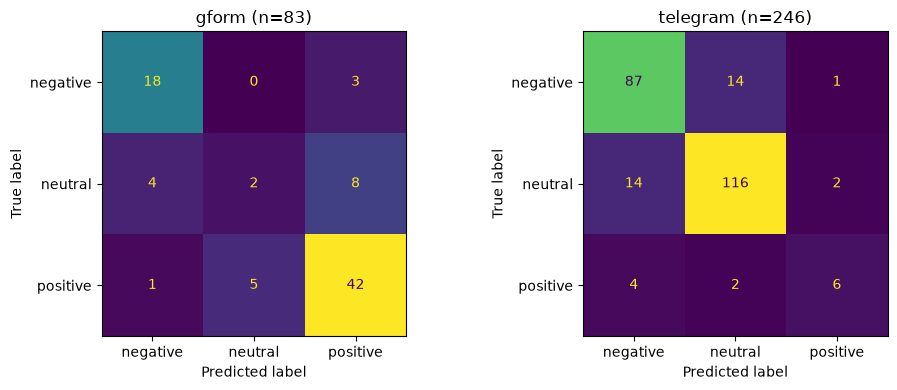

In [13]:
if CHOSEN:
    p = REG[CHOSEN]["test"]
    srcs = sorted(te["source"].unique())
    fig, axes = plt.subplots(1, len(srcs), figsize=(5 * len(srcs), 4), squeeze=False)
    for ax, src in zip(axes[0], srcs):
        m = (te["source"] == src).values
        print(f"\n===== {CHOSEN} | {src} (n={m.sum()}) =====")
        print(classification_report(te.loc[m, "label_sentiment"], p[m], labels=SENT_LABELS, zero_division=0))
        cm = confusion_matrix(te.loc[m, "label_sentiment"], p[m], labels=SENT_LABELS)
        ConfusionMatrixDisplay(cm, display_labels=SENT_LABELS).plot(ax=ax, colorbar=False)
        ax.set_title(f"{src} (n={m.sum()})")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / "sentiment_confusion_test.png", dpi=150) if (OUT_DIR / "figures").exists() else None
    plt.show()

## 11. Terapkan ke seluruh korpus

* Input model: **Telegram** = `text_clean`; **GForm** = pertanyaan + `text_clean` (format yang sama dengan saat pelatihan).
* Dokumen yang sudah punya **label manusia** (gold set) tetap memakai label itu (`sentiment_source = "gold"`); sisanya `"model"`. Dengan begitu dashboard tidak menimpa label manusia dengan tebakan model.
* Prediksi dengan `sentiment_prob < LOW_CONF` ditandai `sentiment_low_conf = True`. **Jangan dihitung di donut dashboard**, atau beri catatan.
* TF-IDF dilatih ulang di **train + val** sebelum diterapkan (test tetap tidak disentuh). Model transformer dipakai apa adanya (tidak dilatih ulang).

In [14]:
assert CHOSEN, "Tidak ada metode dengan probabilitas -> aktifkan tfidf / HF / fine-tuning"
corpus = pd.read_parquet(CORPUS_PATH)

QUESTION = {"wellbeing": "Hal apa yang paling membuat Anda tetap bertahan", "academic": "Apa kendala akademik yang paling sering Anda alami",
            "social": "Apa yang membuat Anda merasa lebih diterima", "career": "Dukungan apa yang paling Anda butuhkan untuk karier",
            "economic": "Ceritakan singkat kesulitan ekonomi yang Anda alami"}   # HARUS sama dengan notebook GForm bagian 8

c = corpus.copy()
c["source"] = c["source"].astype(str)
is_gf = c["source"].eq("gform")
c["model_input"] = c["text_clean"].fillna("").astype(str)
c.loc[is_gf, "model_input"] = c.loc[is_gf, "dimension"].astype(str).map(QUESTION).fillna("") + ": " + c.loc[is_gf, "model_input"]

proba_fn = REG[CHOSEN]["proba_fn"]
if CHOSEN == "tfidf_logreg":
    tv = pd.concat([tr, va])
    vec_f = make_vec(); clf_f = LogisticRegression(C=C_BEST, max_iter=2000, class_weight="balanced")
    clf_f.fit(vec_f.fit_transform(tv["model_input"]), tv["label_sentiment"])
    order = [list(clf_f.classes_).index(k) for k in SENT_LABELS]
    proba_fn = lambda texts: clf_f.predict_proba(vec_f.transform(texts))[:, order]

P = np.vstack([proba_fn(c["model_input"].iloc[i:i + 512]) for i in range(0, len(c), 512)])
c["sentiment"] = to_labels(P)
c["sentiment_prob"] = P.max(1).round(4)
c["sentiment_low_conf"] = c["sentiment_prob"] < LOW_CONF
c["sentiment_source"] = "model"

gold = d[["doc_id", "label_sentiment"]].drop_duplicates("doc_id").set_index("doc_id")["label_sentiment"]
g = c["doc_id"].isin(gold.index)
c.loc[g, "sentiment"] = c.loc[g, "doc_id"].map(gold)
c.loc[g, "sentiment_source"] = "gold"
c.loc[g, "sentiment_low_conf"] = False
if "is_valid" in c:
    bad = (~c["is_valid"].fillna(False).astype(bool)) & ~g
    c.loc[bad, ["sentiment", "sentiment_prob"]] = np.nan
    c.loc[bad, "sentiment_source"] = "invalid"
    c.loc[bad, "sentiment_low_conf"] = True
    print(f"{int(bad.sum())} dokumen tidak valid -> sentimen dikosongkan")
c["sentiment_method"] = CHOSEN

out_cols = ["doc_id", "source", "sentiment", "sentiment_prob", "sentiment_low_conf", "sentiment_source", "sentiment_method"]
out = c[out_cols]
out_path = OUT_DIR / "nadikampus_sentiment.parquet"
out.to_parquet(out_path, index=False)
print(f"{len(out)} dokumen -> {out_path}  (metode: {CHOSEN}; gold: {int(g.sum())})")
display(pd.crosstab(out["source"], out["sentiment"], normalize="index").round(2))
print("Low-confidence:", out.groupby("source")["sentiment_low_conf"].mean().round(2).to_dict())

89 dokumen tidak valid -> sentimen dikosongkan
5433 dokumen -> c:\Users\yuhanidz\Nadi-Kampus-\data\outputs_teks\nadikampus_sentiment.parquet  (metode: indobertweet_ft; gold: 2187)


sentiment,negative,neutral,positive
source,,,
gform,0.25,0.17,0.58
telegram,0.33,0.60,0.08


Low-confidence: {'gform': 0.12, 'telegram': 0.03}


## 12. Cek wajar sebelum dipakai di dashboard

Baca sendiri beberapa prediksi **model** yang yakin dan yang ragu. Ini pemeriksaan kewajaran, bukan pengganti evaluasi test.

In [15]:
m = c[c["sentiment_source"] == "model"]
for src in ["telegram", "gform"]:
    s = m[m["source"] == src]
    if not len(s):
        continue
    print(f"\n#### {src}: 8 prediksi acak yang yakin")
    print(s[~s["sentiment_low_conf"]].sample(min(8, int((~s["sentiment_low_conf"]).sum())), random_state=SEED)[["sentiment", "sentiment_prob", "text_raw"]].to_string(max_colwidth=110))
    print(f"\n#### {src}: 8 prediksi acak yang ragu")
    lc = s[s["sentiment_low_conf"]]
    if len(lc):
        print(lc.sample(min(8, len(lc)), random_state=SEED)[["sentiment", "sentiment_prob", "text_raw"]].to_string(max_colwidth=110))


#### telegram: 8 prediksi acak yang yakin
     sentiment  sentiment_prob                                                                                                       text_raw
2083   neutral          0.9980                                                                       kakak2 d4tb 25 nrp 38 lampu apa ya? 👀😦☝🏻
2322  positive          0.8004                                        mas mas R TB 25 kosong gasii, kok kayanya udah deket sama someone ya 😔😔
313   positive          0.8996  Sekelas dengan doi yang beda tingkat itu peluang nya memang kecil, tapi tidak pernah 0, aww senang nyaa se...
2077  negative          0.9970  mbok sarijem...butuh hiburan, duduk di balkon...tolak-tolakan, pak saringa...cengar-cengir aje, pak safe'i...
85     neutral          0.9971  Info loker part time barista surabaya timur, sekitar area kampus, agak jauh dikit juga gapapa sih, sender ...
957    neutral          0.9971                             guys rekomendasi tws atau IEM dong, budget und

### Setelah ini

1. **Gabungkan ke ekspor web:** `export_student_voice.py` butuh kolom `sentiment`. Baca `data/outputs_teks/nadikampus_sentiment.parquet` lewat `doc_id`, lalu gabungkan dengan hasil topik (`theme`). Hitung donut hanya dari `sentiment_low_conf == False` atau beri catatan.
2. **Untuk laporan:** tulis metode terpilih, Macro F1 per sumber **beserta CI95**, ukuran gold set dan sebaran labelnya, κ antar-pelabel, dan bahwa label LLM (bila dipakai) sudah diverifikasi manusia.
3. **Kalau Telegram terlalu lemah** (Macro F1 rendah, CI lebar): tambah `N_SAMPLE` di notebook Telegram (sampel lama tetap), label ulang bagian tambahannya, ulangi notebook ini.
4. **Jangan di-push ke GitHub:** `nadikampus_sentiment.parquet` dan model hasil fine-tuning (kalau kamu simpan). Hanya `data/student_voice.json` yang boleh.